# v02 — small-object resolution experiment
**You launch training here.** Run the setup and EDA cells in order, inspect their outputs, then change `RUN_TRAIN = False` to `True` in the training cell and run that cell alone. Live batch/epoch progress will appear underneath it. Keep the kernel running and prevent the laptop from sleeping.

Goal: improve MILCO recall **and** precision over v01 (47 TP, 32 FP, 12 FN; 79.66% recall, 59.49% precision on validation). Success is measured with correct class and one-to-one IoU ≥0.50 matching. A higher score is not guaranteed.

One experimental change: **train at 1280 instead of 960**. Keep COCO-pretrained YOLOv8s, raw images, splits, seed 42, SGD and the same epoch budget. Do not initialize from the trained v01 model. AutoBatch adapts resource use to the new resolution.

The supplied splits contain related scenes. The reference notebook already exposed test metrics and test examples. No test data is used here for EDA, tuning or selection; results cannot establish independent-survey generalization.

## 1. Imports and paths
Use the existing project `.venv` in PyCharm. New preparation outputs go to `reports/v02/preparation_review_20261123`; existing results and original data stay intact.

In [1]:
import hashlib
import json
import os
import shutil
import sys
import tempfile
import time
import urllib.request
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from IPython.display import display
from ultralytics import YOLO

print('Imports ready')

Imports ready


In [2]:
ROOT = Path.cwd().resolve()
if ROOT.name == 'src':
    ROOT = ROOT.parent
if not (ROOT / 'pyproject.toml').is_file():
    raise FileNotFoundError('Start the notebook from the project root or src directory.')
DATA = ROOT / 'dataset'
WORK = ROOT / 'reports/v02/preparation_review_20261123'
WORK.mkdir(parents=True, exist_ok=True)
NAMES = {0: 'MILCO', 1: 'NonMILCO'}
print('Project:', ROOT)
print('Outputs:', WORK)

Project: /home/escape/Projects/mine-detection-using-YOLOv8-transfer-learning
Outputs: /home/escape/Projects/mine-detection-using-YOLOv8-transfer-learning/reports/v02/preparation_review_20261123


In [3]:
splits = ('train', 'val', 'test')
missing = [split for split in splits if not (DATA / split).exists()]
if missing:
    if len(missing) != len(splits):
        raise FileNotFoundError(f'Incomplete dataset: missing {missing}; preserve existing files and restore manually.')
    url = 'https://github.com/AkshatTandekar07/mine-detection-using-YOLOv8-transfer-learning/releases/download/v1.0.0/sonar_dataset.zip'
    print('Downloading dataset to temporary storage...')
    with tempfile.TemporaryDirectory(dir=ROOT) as temp:
        archive = Path(temp) / 'dataset.zip'
        extracted = Path(temp) / 'extracted'
        urllib.request.urlretrieve(url, archive)
        shutil.unpack_archive(archive, extracted)
        source = extracted / 'dataset' if (extracted / 'dataset').is_dir() else extracted
        for split in splits:
            for folder in ('images', 'labels'):
                if not (source / split / split / folder).is_dir():
                    raise ValueError(f'Archive missing {split}/{split}/{folder}')
        if not (DATA / 'mine.yaml').is_file() and not (source / 'mine.yaml').is_file():
            raise ValueError('Dataset archive is missing mine.yaml')
        DATA.mkdir(parents=True, exist_ok=True)
        if not (DATA / 'mine.yaml').exists():
            shutil.copy2(source / 'mine.yaml', DATA / 'mine.yaml')
        for split in splits:
            shutil.move(str(source / split), str(DATA / split))
print('Dataset:', DATA)

Dataset: /home/escape/Projects/mine-detection-using-YOLOv8-transfer-learning/dataset


In [4]:
required = [DATA / 'mine.yaml']
required += [DATA / split / split / folder for split in splits for folder in ('images', 'labels')]
missing_paths = [str(path) for path in required if not path.exists()]
if missing_paths:
    raise FileNotFoundError(f'Incomplete dataset; restore missing paths: {missing_paths}')
print('Dataset layout verified for train, val and test.')

Dataset layout verified for train, val and test.


In [5]:
import platform
import subprocess
import psutil
import ultralytics
import yaml

print('Python:', sys.executable, sys.version)
print('Platform:', platform.platform())
print('PyTorch:', torch.__version__, 'CUDA build:', torch.version.cuda)
print('Ultralytics:', ultralytics.__version__)
memory = psutil.virtual_memory()
swap = psutil.swap_memory()
print('RAM total / available GiB:', round(memory.total / 2**30, 2), round(memory.available / 2**30, 2))
print('Swap total / free GiB:', round(swap.total / 2**30, 2), round(swap.free / 2**30, 2))
print('Free disk GiB:', round(shutil.disk_usage(WORK).free / 2**30, 2))
if ultralytics.__version__ != '8.4.215':
    raise RuntimeError(f'Expected Ultralytics 8.4.215, found {ultralytics.__version__}; review before comparison.')
print('Environment version check passed.')

Python: /home/escape/Projects/mine-detection-using-YOLOv8-transfer-learning/.venv/bin/python 3.12.16 (main, Oct 26 2026, 14:08:45) [Clang 23.1.3 ]
Platform: Linux-7.0.0-43-generic-x86_64-with-glibc2.43
PyTorch: 2.15.0+cu132 CUDA build: 13.2
Ultralytics: 8.4.215
RAM total / available GiB: 14.42 4.39
Swap total / free GiB: 4.0 2.09
Free disk GiB: 84.12
Environment version check passed.


In [6]:
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
if shutil.which('nvidia-smi'):
    gpu_status = subprocess.run(['nvidia-smi'], capture_output=True, text=True)
    print(gpu_status.stdout or gpu_status.stderr)
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
    print('Free / total VRAM GiB:', [round(v / 2**30, 2) for v in torch.cuda.mem_get_info()])
else:
    print('CUDA unavailable: EDA is usable, but do not start CPU training.')
print('Selected device:', DEVICE)

Mon Nov 23 06:45:51 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 615.71.09              KMD Version: 615.71.09     CUDA UMD Version: 13.4     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 5060 ...    Off |   00000000:01:00.0  On |                  N/A |
| N/A   44C    P5             14W /   45W |     172MiB /   8151MiB |     34%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Known baseline and data inventory
These are saved **validation** results, not a new v02 result. Read only train/validation annotations. Empty labels count as background to the trainer, not as confirmed NonMILCO objects or confirmed safe scenes.

In [7]:
baseline = json.loads((ROOT / 'reports/v01/selected_settings.json').read_text())
assert baseline['sha256'] == '6059aac2d77cbc9cbb560969d00d72d4ed39b7482c84f4686ccaa977747869d9'
baseline_table = pd.DataFrame(baseline['metrics'])
baseline_table['class'] = baseline_table.cls.map(NAMES)
BASE_RECALL = float(baseline_table.loc[baseline_table.cls == 0, 'recall'].iloc[0])
BASE_PRECISION = float(baseline_table.loc[baseline_table.cls == 0, 'precision'].iloc[0])
assert yaml.safe_load((DATA / 'mine.yaml').read_text())['names'] == list(NAMES.values())
print('v01 selected size/confidence:', baseline['imgsz'], baseline['conf'])
display(baseline_table[['class', 'TP', 'FP', 'FN', 'precision', 'recall']])

v01 selected size/confidence: 960 0.05


,class,TP,FP,FN,precision,recall
0,MILCO,47,32,12,0.594937,0.796610
1,NonMILCO,19,58,15,0.246753,0.558824


In [8]:
files = []
for split in ['train', 'val']:
    base = DATA / split / split
    images = sorted((base / 'images').glob('*.jpg'))
    labels = sorted((base / 'labels').glob('*.txt'))
    assert len(images) == {'train': 819, 'val': 176}[split]
    assert {p.stem for p in images} == {p.stem for p in labels}
    for image in images:
        label = base / 'labels' / (image.stem + '.txt')
        files.append(dict(split=split, image=image, label=label, name=image.stem))
files = pd.DataFrame(files)
print('Paired image/label files:', files.shape)
display(files.head())

Paired image/label files: (995, 4)


,split,image,label,name
0,train,/home/escape/Projects/mine-detection-using-YOL...,/home/escape/Projects/mine-detection-using-YOL...,0001_2018
1,train,/home/escape/Projects/mine-detection-using-YOL...,/home/escape/Projects/mine-detection-using-YOL...,0001_2021
2,train,/home/escape/Projects/mine-detection-using-YOL...,/home/escape/Projects/mine-detection-using-YOL...,0002_2010
3,train,/home/escape/Projects/mine-detection-using-YOL...,/home/escape/Projects/mine-detection-using-YOL...,0002_2015
4,train,/home/escape/Projects/mine-detection-using-YOL...,/home/escape/Projects/mine-detection-using-YOL...,0002_2017


In [9]:
def read_labels(path):
    rows = [list(map(float, line.split())) for line in path.read_text().splitlines() if line.strip()]
    assert all(len(row) == 5 for row in rows), path
    labels = np.array(rows, dtype=float).reshape(-1, 5)
    assert np.isfinite(labels).all(), path
    assert np.isin(labels[:, 0], [0, 1]).all(), path
    assert ((labels[:, 1:3] >= 0) & (labels[:, 1:3] <= 1)).all(), path
    assert ((labels[:, 3:5] > 0) & (labels[:, 3:5] <= 1)).all(), path
    return labels

print('Example raw labels:', read_labels(files.iloc[0].label))

Example raw labels: []


In [10]:
from tempfile import TemporaryDirectory
with TemporaryDirectory() as temporary:
    bad = Path(temporary) / 'bad.txt'
    bad.write_text('0 0.5 0.5 0.1\n0 0.5 0.5 0.1 0.1 0.1')
    try:
        read_labels(bad)
    except AssertionError:
        pass
    else:
        raise AssertionError('Mixed malformed row lengths were accepted')
print('Malformed annotation check passed')

Malformed annotation check passed


## 3. EDA — image size, empty labels and object counts
Decode every train/validation image, validate each label, and record fingerprints. Inspect all annotations without silently fixing them. Image names and year-like suffixes are clues, not verified acquisition metadata.

In [11]:
image_rows, box_rows, fingerprints = [], [], {}
for item in files.itertuples():
    labels = read_labels(item.label)
    with Image.open(item.image) as image:
        image.load()
        width, height = image.size
        gray = np.asarray(image.convert('L'))
        brightness, contrast = float(gray.mean()), float(gray.std())
    image_rows.append(dict(split=item.split, name=item.name, width=width, height=height,
        objects=len(labels), empty=len(labels) == 0, brightness=brightness, contrast=contrast))
    for row, (cls, x, y, w, h) in enumerate(labels, 1):
        box_rows.append(dict(split=item.split, name=item.name, row=row, cls=int(cls),
            x=x, y=y, w=w, h=h, min_side_960=min(w*width,h*height)*960/max(width,height),
            min_side_1280=min(w*width,h*height)*1280/max(width,height),
            outside=min(x-w/2,y-h/2)<0 or max(x+w/2,y+h/2)>1))
    for path in [item.image, item.label]:
        fingerprints[str(path.relative_to(DATA))] = hashlib.sha256(path.read_bytes()).hexdigest()
images_df, boxes_df = pd.DataFrame(image_rows), pd.DataFrame(box_rows)
print('Images:', images_df.shape, 'annotation rows:', boxes_df.shape)
display(images_df.head())

Images: (995, 8) annotation rows: (586, 11)


,split,name,width,height,objects,empty,brightness,contrast
0,train,0001_2018,1024,1024,0,True,47.386057,45.211539
1,train,0001_2021,416,416,2,False,41.442984,32.832720
2,train,0002_2010,1024,1024,0,True,49.597856,34.065386
3,train,0002_2015,416,416,5,False,44.224777,29.891406
4,train,0002_2017,416,416,2,False,46.698410,34.038993


In [12]:
summary = images_df.groupby('split').agg(images=('name', 'size'), empty=('empty', 'sum'),
                                          objects=('objects', 'sum'))
class_counts = pd.crosstab(boxes_df.split, boxes_df.cls).rename(columns=NAMES)
summary = summary.join(class_counts)
assert summary.loc['train', 'MILCO'] == 315 and summary.loc['val', 'MILCO'] == 59
assert summary.loc['train', 'empty'] == 594 and summary.loc['val', 'empty'] == 133
baseline_manifest = ROOT / 'reports/v01/input_manifest.json'
BASELINE_INPUTS_VERIFIED = False
if baseline_manifest.is_file():
    if fingerprints != json.loads(baseline_manifest.read_text()):
        raise ValueError('Inputs differ from v01; investigate before proceeding.')
    BASELINE_INPUTS_VERIFIED = True
else:
    print('WARNING: v01 manifest missing; input equivalence cannot be verified.')
(WORK / 'input_manifest.json').write_text(json.dumps(fingerprints, indent=2))
summary.to_csv(WORK / 'eda_summary.csv')
print('Class counts are objects, not numbers of images containing a class.')
display(summary)

Class counts are objects, not numbers of images containing a class.


,images,empty,objects,MILCO,NonMILCO
split,,,,,
train,819,594,493,315,178
val,176,133,93,59,34


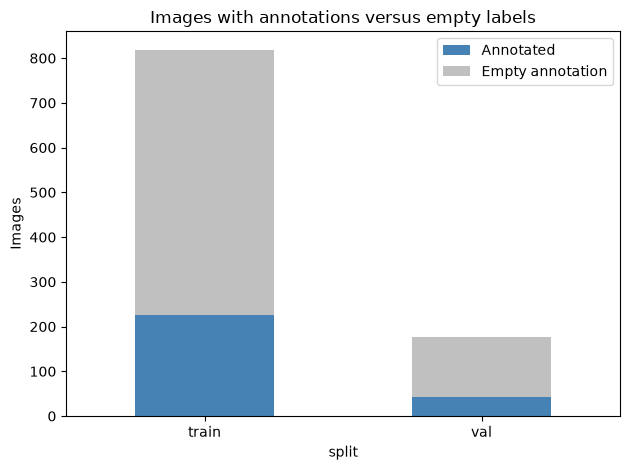

In [13]:
background_counts = pd.crosstab(images_df['split'], images_df['empty'])
background_counts.columns = ['Annotated', 'Empty annotation']
background_counts.plot.bar(stacked=True, color=['steelblue', 'silver'], rot=0)
plt.ylabel('Images')
plt.title('Images with annotations versus empty labels')
plt.tight_layout()
plt.show()

images
split width height        
train 416   416        408
      1024  1024       411
val   416   416         90
      1024  1024        86

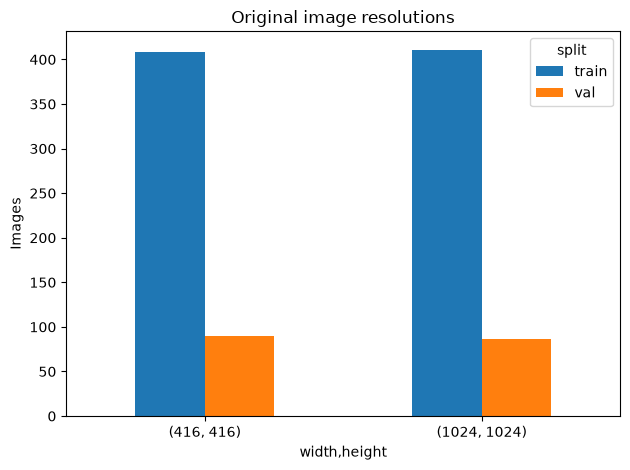

In [14]:
resolution_counts = images_df.groupby(['split', 'width', 'height']).size().rename('images')
display(resolution_counts.to_frame())
resolution_counts.unstack('split').plot.bar(rot=0)
plt.ylabel('Images')
plt.title('Original image resolutions')
plt.tight_layout()
plt.show()

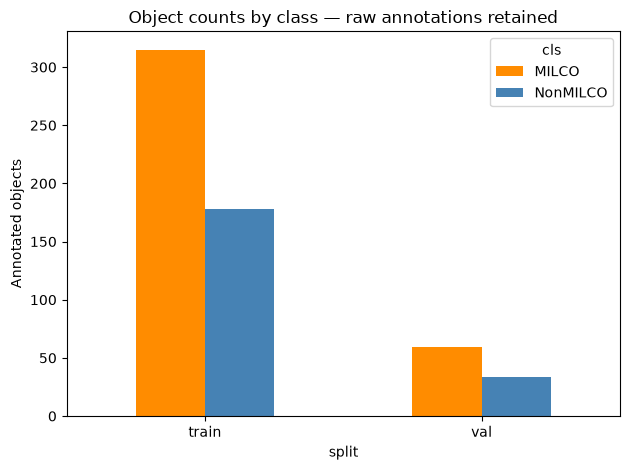

In [15]:
class_counts.plot.bar(rot=0, color=['darkorange', 'steelblue'])
plt.ylabel('Annotated objects')
plt.title('Object counts by class — raw annotations retained')
plt.tight_layout()
plt.show()

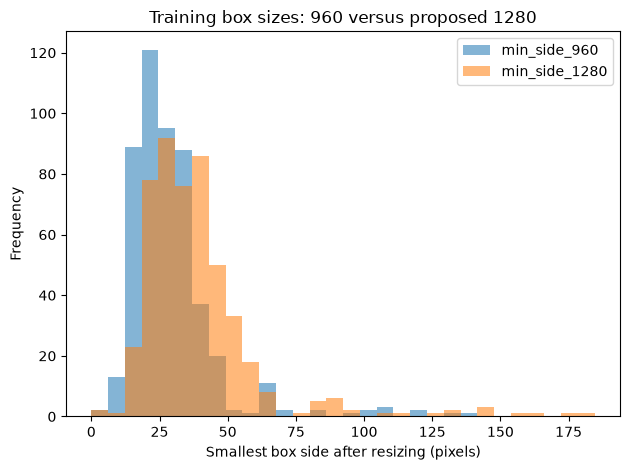

In [16]:
train_boxes = boxes_df[boxes_df.split == 'train']
train_boxes[['min_side_960', 'min_side_1280']].plot.hist(bins=30, alpha=0.55)
plt.xlabel('Smallest box side after resizing (pixels)')
plt.title('Training box sizes: 960 versus proposed 1280')
plt.tight_layout()
plt.show()

In [17]:
small_boxes = []
for split in ['train', 'val']:
    for cls in NAMES:
        group = boxes_df[(boxes_df.split == split) & (boxes_df.cls == cls)]
        small_boxes.append(dict(split=split, cls=NAMES[cls], objects=len(group),
            below_8px_960=int((group.min_side_960 < 8).sum()),
            below_8px_1280=int((group.min_side_1280 < 8).sum())))
print('Upsampling gives more pixels, not new acoustic detail.')
display(pd.DataFrame(small_boxes))

Upsampling gives more pixels, not new acoustic detail.


,split,cls,objects,below_8px_960,below_8px_1280
0,train,MILCO,315,2,2
1,train,NonMILCO,178,0,0
2,val,MILCO,59,0,0
3,val,NonMILCO,34,0,0


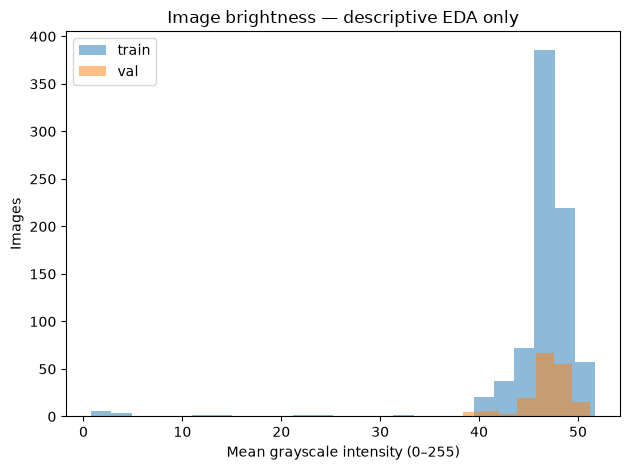

In [18]:
for split in ['train', 'val']:
    values = images_df.loc[images_df.split == split, 'brightness']
    plt.hist(values, bins=25, alpha=0.5, label=split)
plt.xlabel('Mean grayscale intensity (0–255)')
plt.ylabel('Images')
plt.title('Image brightness — descriptive EDA only')
plt.legend()
plt.tight_layout()
plt.show()

### Inspect the flagged annotation
The tiny row is left unchanged. The native verifier accepts it; standard augmentation clips/transforms boxes and may filter tiny transformed boxes in memory. This is the same loader policy as v01, not an annotation correction.

In [19]:
flagged = boxes_df[boxes_df.outside]
assert flagged[['split', 'name', 'row']].values.tolist() == [['train', '0367_2018', 2]]
flag_path = DATA / 'train/train/labels/0367_2018.txt'
print(flag_path.read_text())
from ultralytics.data.utils import verify_image_label
checked = verify_image_label((str(DATA / 'train/train/images/0367_2018.jpg'),
    str(flag_path), '', False, 2, 0, 0, False))
assert checked[8] == 0 and len(checked[1]) == 2
np.testing.assert_allclose(checked[1], read_labels(flag_path))
display(flagged)

0 0.12060546875 0.0400390625 0.1416015625 0.029296875
0 0 0.00008296966552734375 0.00000476837158203125 0.000030517578125


,split,name,row,cls,x,y,w,h,min_side_960,min_side_1280,outside
440,train,0367_2018,2,0,0.0,0.000083,0.000005,0.000031,0.004578,0.006104,True


### Annotated and empty examples
Use a deterministic, evenly spaced sample of four annotated training images, plus four empty-label training images. This is a visual sample, not evidence that every label is complete. The boxes show exactly the recorded geometry.

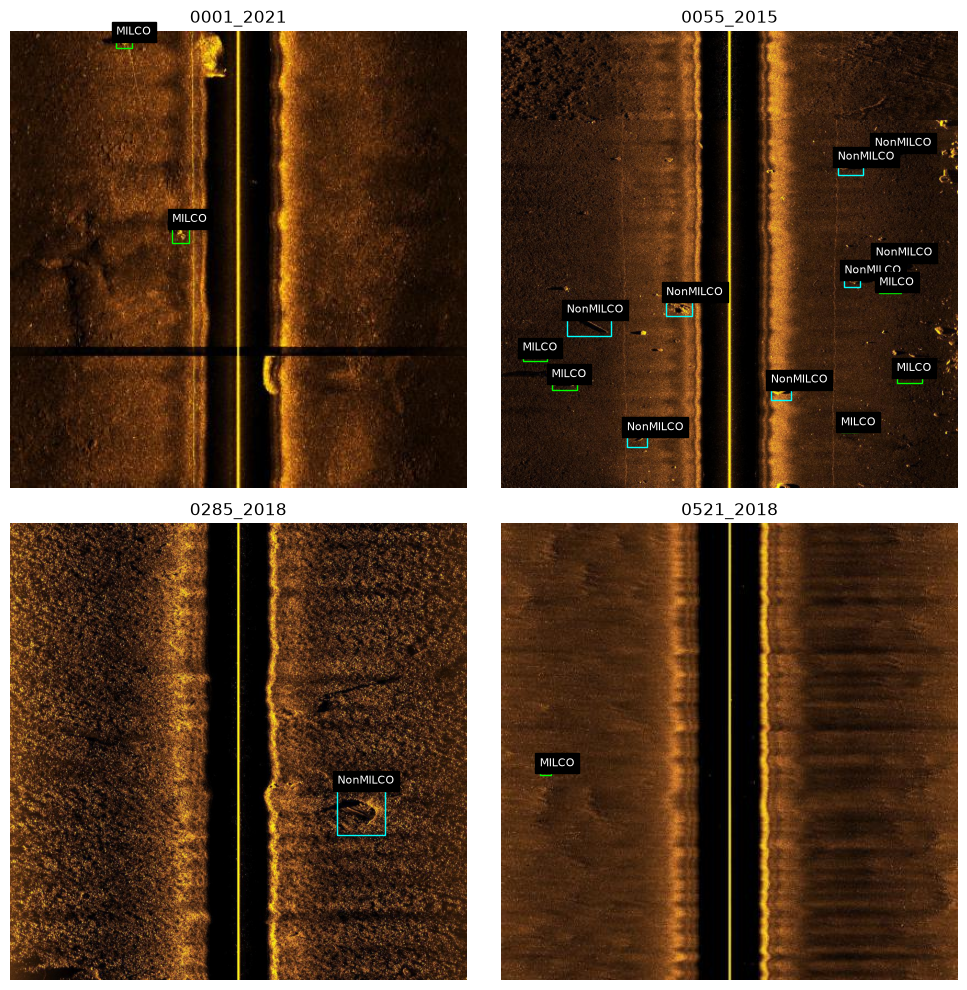

In [20]:
from matplotlib.patches import Rectangle
annotated = images_df[(images_df.split == 'train') & ~images_df['empty']]
chosen = annotated.iloc[np.linspace(0, len(annotated)-1, 4, dtype=int)]
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
for ax, item in zip(axes.flat, chosen.itertuples()):
    image = Image.open(DATA / 'train/train/images' / (item.name + '.jpg'))
    ax.imshow(image)
    for box in boxes_df[(boxes_df.split == 'train') & (boxes_df.name == item.name)].itertuples():
        x, y = (box.x-box.w/2)*item.width, (box.y-box.h/2)*item.height
        ax.add_patch(Rectangle((x,y),box.w*item.width,box.h*item.height,
                              fill=False,edgecolor='lime' if box.cls==0 else 'cyan'))
        ax.text(x,y,NAMES[box.cls],color='white',backgroundcolor='black',fontsize=8)
    ax.set_title(item.name)
    ax.axis('off')
plt.tight_layout()
plt.show()

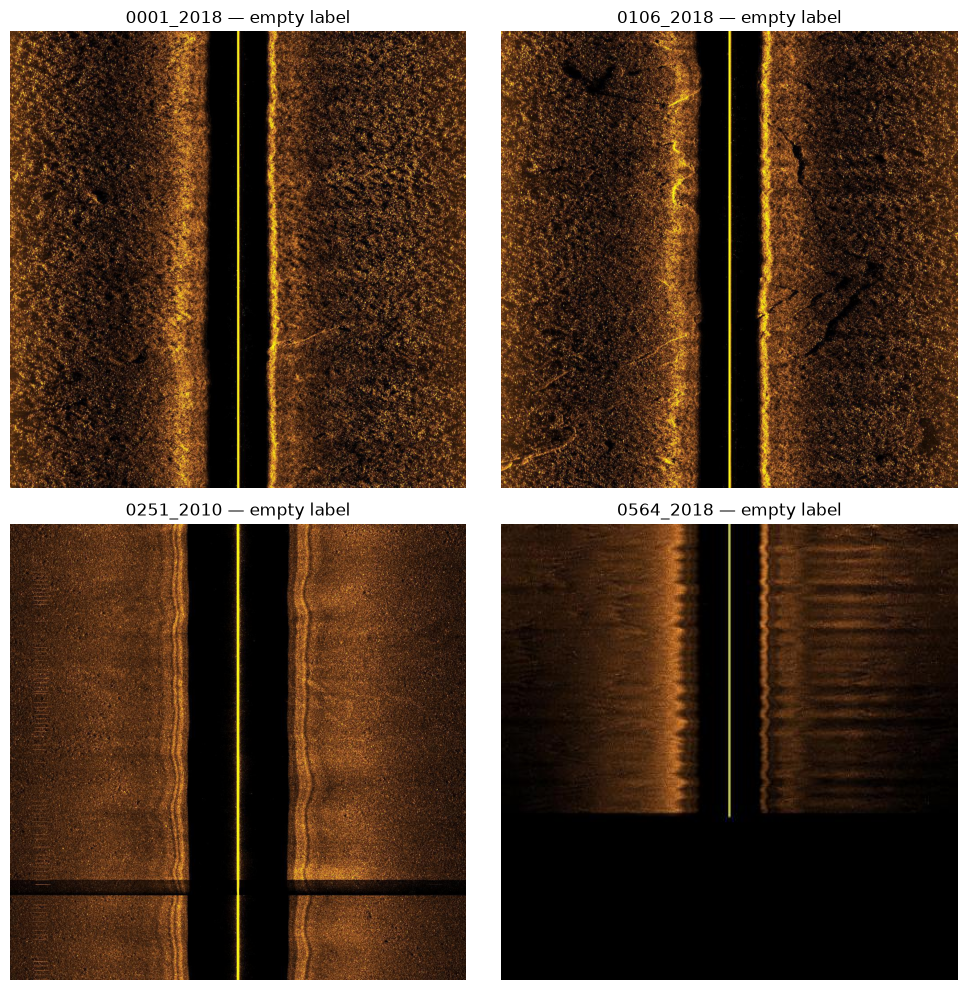

In [21]:
empty_images = images_df[(images_df.split == 'train') & images_df['empty']]
chosen_empty = empty_images.iloc[np.linspace(0,len(empty_images)-1,4,dtype=int)]
fig, axes = plt.subplots(2,2,figsize=(10,10))
for ax, item in zip(axes.flat, chosen_empty.itertuples()):
    with Image.open(DATA / 'train/train/images' / (item.name+'.jpg')) as image:
        ax.imshow(image)
    ax.set_title(item.name + ' — empty label')
    ax.axis('off')
plt.tight_layout()
plt.show()

### Related-image leakage warning
The earlier audit found no byte-identical image duplicates, yet visually related scenes cross splits. Inspect one verified train/validation pair below. Shared scene content can inflate benchmark performance. Source grouping, annotation policy and license remain unresolved; keep supplied splits unchanged.

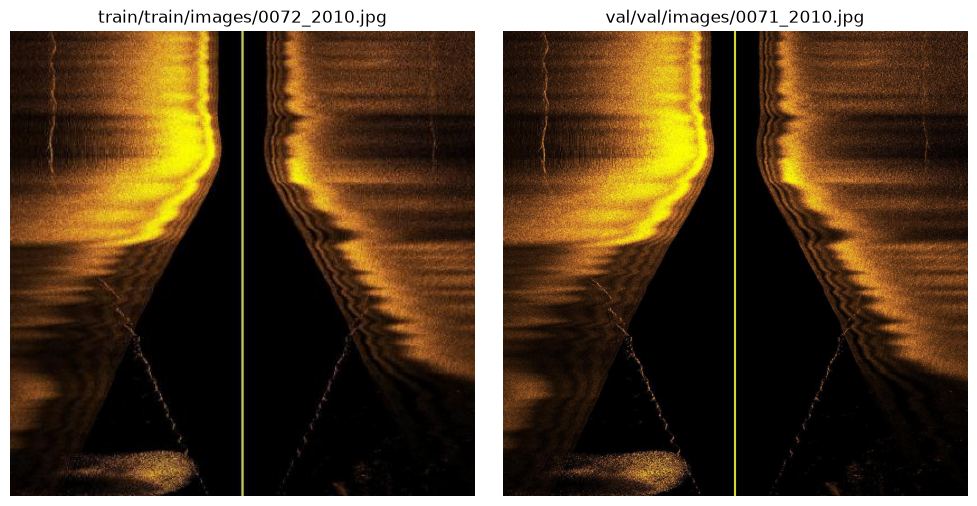

In [22]:
related = [DATA / 'train/train/images/0072_2010.jpg',
           DATA / 'val/val/images/0071_2010.jpg']
fig, axes = plt.subplots(1,2,figsize=(10,5))
for ax, path in zip(axes,related):
    with Image.open(path) as image:
        ax.imshow(image)
    ax.set_title(str(path.relative_to(DATA)))
    ax.axis('off')
plt.tight_layout()
plt.show()

## 4. Protect the original dataset and check pretrained weights
Copy the recorded train/validation files into a new working tree. Match bytes and filenames exactly so caches cannot touch originals or v01. No test path is included in the new YAML.

In [23]:
STAGED = WORK / 'data'
for relative, digest in fingerprints.items():
    source, destination = DATA / relative, STAGED / relative
    destination.parent.mkdir(parents=True, exist_ok=True)
    if not destination.exists():
        shutil.copy2(source, destination)
    assert hashlib.sha256(destination.read_bytes()).hexdigest() == digest, destination
for split in ['train','val']:
    for folder, pattern in [('images','*'),('labels','*.txt')]:
        actual = {str(p.relative_to(STAGED)) for p in (STAGED/split/split/folder).glob(pattern)}
        expected = {p for p in fingerprints if p.startswith(f'{split}/{split}/{folder}/')}
        assert actual == expected, 'Unexpected staged inputs'
CONFIG = WORK / 'sonar.yaml'
CONFIG.write_text(yaml.safe_dump({'path':str(STAGED.resolve()),'train':'train/train/images',
    'val':'val/val/images','names':NAMES}))
print('Verified copied files:',len(fingerprints))
print(CONFIG.read_text())

Verified copied files: 1990
names:
  0: MILCO
  1: NonMILCO
path: /home/escape/Projects/mine-detection-using-YOLOv8-transfer-learning/reports/v02/preparation_review_20261123/data
train: train/train/images
val: val/val/images



In [24]:
WEIGHTS = ROOT / 'src/yolov8s.pt'
PRETRAINED_HASH = None
if WEIGHTS.is_file():
    PRETRAINED_HASH = hashlib.sha256(WEIGHTS.read_bytes()).hexdigest()
    model = YOLO(str(WEIGHTS))
    assert len(model.names) == 80 and model.ckpt['train_args']['data'] == 'coco.yaml'
    print('Loaded COCO pretrained YOLOv8s:', WEIGHTS)
    print('SHA-256:', PRETRAINED_HASH)
else:
    print('Pretrained weights not found at', WEIGHTS, '— model check skipped.')

Loaded COCO pretrained YOLOv8s: /home/escape/Projects/mine-detection-using-YOLOv8-transfer-learning/src/yolov8s.pt
SHA-256: 1f47a78bf100391c2a140b7ac73a1caae18c32779be7d310658112f7ac9aa78a


## 5. Experiment settings and visible progress
1280 requires about **1.78×** the pixels of 960. AutoBatch targets 60% GPU memory; do not assume batch 8 is the limit. Keep workers=0 and no RAM image cache. A single forward pass below checks model execution, not training memory capacity. AutoBatch will profile that when you launch.

The epoch callback prints training percentage, elapsed time and a rough remaining time, and saves `progress.csv`. Its message marks training batches completed for the epoch; validation follows. Early stopping may finish before 100 epochs. The normal Ultralytics output underneath the training cell also shows batch progress and validation summaries.

In [25]:
IMGSZ, EPOCHS = 1280, 100
RUN = WORK / 'runs/yolov8s_v02_1280'
settings = dict(data=str(CONFIG),epochs=EPOCHS,imgsz=IMGSZ,batch=0.60,
    optimizer='SGD',lr0=0.01,momentum=0.937,weight_decay=0.0005,
    patience=20,device=0,workers=0,cache=False,seed=42,
    project=str(WORK/'runs'),name=RUN.name,exist_ok=False,
    plots=True,save=True,save_period=10,verbose=True)
print('Only experimental training change versus v01: imgsz 960 →',IMGSZ)
print('Pixels relative to v01:',round((IMGSZ/960)**2,2))
display(pd.Series(settings,name='Training settings'))

Only experimental training change versus v01: imgsz 960 → 1280
Pixels relative to v01: 1.78


data            /home/escape/Projects/mine-detection-using-YOL...
epochs                                                        100
imgsz                                                        1280
batch                                                         0.6
optimizer                                                     SGD
lr0                                                          0.01
momentum                                                    0.937
weight_decay                                               0.0005
patience                                                       20
device                                                          0
workers                                                         0
cache                                                       False
seed                                                           42
project         /home/escape/Projects/mine-detection-using-YOL...
name                                             yolov8s_v02_1280
exist_ok  

In [26]:
example = DATA / 'train/train/images/0001_2021.jpg'
with Image.open(example) as image:
    print('Example image size:', image.size)
print('Model inference skipped; inference remains disabled.')

Example image size: (416, 416)
Model inference skipped; inference remains disabled.


In [27]:
def progress_text(done: int, total: int, elapsed: float) -> str:
    assert 1 <= done <= total and elapsed >= 0
    remaining = elapsed / done * (total-done)
    return (f'Training epoch {done}/{total} ({100*done/total:.1f}%) | '
            f'elapsed {elapsed/60:.1f} min | rough remaining {remaining/60:.1f} min | validation next')

assert '50.0%' in progress_text(50,100,600)
assert 'remaining 0.0 min' in progress_text(100,100,1200)
print('Synthetic progress display check (no training):')
print(progress_text(25,100,300))

Synthetic progress display check (no training):
Training epoch 25/100 (25.0%) | elapsed 5.0 min | rough remaining 15.0 min | validation next


In [28]:
PROGRESS = WORK / 'progress.csv'
def print_epoch_progress(trainer):
    done, total = trainer.epoch+1, trainer.epochs
    elapsed = time.time()-trainer.train_time_start
    print(progress_text(done,total,elapsed),flush=True)
    row = pd.DataFrame([dict(epoch=done,total_epochs=total,
        percent=100*done/total,elapsed_seconds=elapsed)])
    row.to_csv(PROGRESS,mode='a',header=not PROGRESS.exists(),index=False)

# Check formatting and CSV fields without invoking training or writing progress.csv.
print('Progress output file:',PROGRESS)
print('Existing progress rows:',len(pd.read_csv(PROGRESS)) if PROGRESS.exists() else 0)

Progress output file: /home/escape/Projects/mine-detection-using-YOLOv8-transfer-learning/reports/v02/preparation_review_20261123/progress.csv
Existing progress rows: 0


In [29]:
from types import SimpleNamespace
with TemporaryDirectory() as temporary:
    saved_progress = PROGRESS
    PROGRESS = Path(temporary) / 'progress.csv'
    simulated = SimpleNamespace(epoch=0,epochs=100,train_time_start=time.time()-60)
    print('Synthetic callback test; no model training is being run:')
    print_epoch_progress(simulated)
    saved = pd.read_csv(PROGRESS)
    assert saved.epoch.tolist() == [1] and saved.percent.tolist() == [1.0]
    PROGRESS = saved_progress
    display(saved)
print('Real training progress path remains:',PROGRESS)

Synthetic callback test; no model training is being run:
Training epoch 1/100 (1.0%) | elapsed 1.0 min | rough remaining 99.0 min | validation next


,epoch,total_epochs,percent,elapsed_seconds
0,1,100,1.0,60.000145


Real training progress path remains: /home/escape/Projects/mine-detection-using-YOLOv8-transfer-learning/reports/v02/preparation_review_20261123/progress.csv


## 6. YOUR TRAINING CELL — stop here

Training is disabled. Before considering a launch, restore the original `reports/v01/input_manifest.json`, provide COCO-pretrained `yolov8s.pt` at `src/yolov8s.pt`, and rerun preparation to verify them. Review hardware, existing results and the experiment settings.

If you later choose to train, set `RUN_TRAIN = True` and run this cell alone in the notebook kernel. Preserve existing results and keep PyCharm and the computer awake. After training, save the notebook and bring back the run directory, progress CSV, environment record and any traceback. Evaluation and inference remain disabled.

In [ ]:
RUN_TRAIN = False
if RUN_TRAIN:
    assert BASELINE_INPUTS_VERIFIED, 'Restore the original v01 input manifest before training'
    assert PRETRAINED_HASH is not None, 'Provide COCO pretrained weights before training'
    assert torch.cuda.is_available(), 'Select a working CUDA GPU before training'
    assert not RUN.exists(), 'Existing run: inspect it before starting anything new'
    assert not PROGRESS.exists(), 'Preserve existing progress; inspect the previous attempt'
    environment = dict(python=sys.version,torch=torch.__version__,ultralytics=ultralytics.__version__,
        gpu=torch.cuda.get_device_name(0),free_total_vram=list(torch.cuda.mem_get_info()),
        pretrained_sha256=PRETRAINED_HASH,settings=settings)
    (WORK/'training_environment.json').write_text(json.dumps(environment,indent=2))
    model = YOLO(str(WEIGHTS))
    model.add_callback('on_train_epoch_end',print_epoch_progress)
    training_results = model.train(**settings)
    print('Training returned. Saved run:',model.trainer.save_dir)
else:
    print('Training disabled. Set RUN_TRAIN=True and run ONLY this cell when ready.')
print('Expected weights:',RUN/'weights/best.pt')

## 7. After training — inspect completion first
These cells are prepared for after you return with the completed training. They stay disabled now. No training is launched by evaluation. Keep the saved training flag false before rerunning setup or using Run All.

Verify 100 completed epochs or a recorded early-stopping decision, then inspect the saved checkpoint. An existing partial checkpoint alone is not proof of completion.

In [ ]:
RUN_EVALUATION = False
if RUN_EVALUATION:
    history = pd.read_csv(RUN / 'results.csv')
    CHECKPOINT = RUN / 'weights/best.pt'
    MODEL_URL = 'https://github.com/AkshatTandekar07/mine-detection-using-YOLOv8-transfer-learning/releases/download/v1.0.0/best_1280.pt'
    if not CHECKPOINT.exists():
        print('Downloading fine-tuned weights best_1280.pt from GitHub Release...')
        CHECKPOINT.parent.mkdir(parents=True, exist_ok=True)
        import urllib.request
        urllib.request.urlretrieve(MODEL_URL, CHECKPOINT)
        print('Downloaded weights successfully!')
    assert CHECKPOINT.exists(), 'No saved best checkpoint'
    print('Recorded epochs:', len(history), 'last epoch:', history.epoch.iloc[-1])
    display(history.tail())
else:
    print('Evaluation disabled until training completes and the run is reviewed.')

In [ ]:
if RUN_EVALUATION:
    history.plot(x='epoch',y=['metrics/mAP50(B)','metrics/mAP50-95(B)'])
    plt.ylabel('Validation AP')
    plt.title('Training history — confidence-sweep summaries')
    plt.tight_layout()
    plt.show()
else:
    print('No training-history plot: evaluation is disabled.')

### One-to-one metric checks
Keep v01's confidence-ordered matching rule: same class, highest IoU among unmatched annotations, IoU ≥0.50. Duplicate or wrong-class predictions count as FP; unmatched annotations count as FN. Include every validation image, including empty annotations. NMS IoU 0.70 is distinct from matching IoU 0.50.

In [ ]:
from ultralytics.utils.metrics import box_iou

def detection_counts(predictions, truth):
    # predictions: class, confidence, x1, y1, x2, y2; truth: class, x1, y1, x2, y2
    counts = np.zeros((2, 3), dtype=int)  # TP, FP, FN
    used = set()
    for p in sorted(predictions, key=lambda row: -row[1]):
        cls = int(p[0])
        candidates = [i for i, g in enumerate(truth) if int(g[0]) == cls and i not in used]
        match = None
        if candidates:
            overlaps = box_iou(torch.as_tensor(np.asarray(p[2:])[None], dtype=torch.float32),
                               torch.tensor(truth[candidates, 1:], dtype=torch.float32))[0].numpy()
            best = int(overlaps.argmax())
            if overlaps[best] >= 0.50:
                match = candidates[best]
        if match is None:
            counts[cls, 1] += 1
        else:
            used.add(match)
            counts[cls, 0] += 1
    for i, g in enumerate(truth):
        counts[int(g[0]), 2] += i not in used
    return counts
print('Matching example label rows:',read_labels(files.iloc[0].label).shape)

In [ ]:
truth = np.array([[0, 0, 0, 10, 10], [1, 20, 20, 30, 30]], dtype=float)
pred = np.array([[0, .9, 0, 0, 10, 10], [0, .8, 0, 0, 10, 10],
                 [0, .7, 20, 20, 30, 30]], dtype=float)
assert detection_counts(pred, truth).tolist() == [[1, 2, 0], [0, 0, 1]]
assert detection_counts([], truth).tolist() == [[0, 0, 1], [0, 0, 1]]
assert detection_counts(pred, np.empty((0, 5))).tolist() == [[0, 3, 0], [0, 0, 0]]
assert detection_counts([[0, .9, 0, 0, 5, 10]], truth).tolist() == [[1, 0, 0], [0, 0, 1]]
assert detection_counts([[0, .9, 0, 0, 4.9, 10]], truth).tolist() == [[0, 1, 1], [0, 0, 1]]
print('Matching checks passed')

In [ ]:
def validation_predictions(detector, size):
    records = []
    results = detector.predict(source=str(STAGED / 'val/val/images'), stream=True,
        imgsz=size, conf=0.001, iou=0.70, max_det=300, agnostic_nms=False,
        device=DEVICE, batch=1, verbose=False, save=False)
    for result in results:
        labels = read_labels(STAGED / 'val/val/labels' / (Path(result.path).stem + '.txt'))
        h, w = result.orig_shape
        centers = labels[:, 1:3] * [w, h]
        halves = labels[:, 3:5] * [w, h] / 2
        truth = np.column_stack((labels[:, 0], centers-halves, centers+halves))
        boxes = result.boxes
        predictions = np.column_stack((boxes.cls.cpu(), boxes.conf.cpu(), boxes.xyxy.cpu()))
        records.append((predictions, truth))
    assert len(records) == 176
    return records
print('Validation images available:',len(list((STAGED/'val/val/images').glob('*.jpg'))))

### Validation grid and comparison with v01
Predeclare inference sizes **960 and 1280**, confidence grid **.001, .01, .025, .05, .1, .15, .25, .4, .6**, class-aware NMS .70, max_det 300. One confidence is shared by both classes. This changes no test settings based on test performance.

First seek **both** MILCO recall >79.66% and precision >59.49% (v01's selected result). If feasible, prefer highest precision then highest recall. Otherwise explicitly report no simultaneous improvement and use v01's fallback rule: fewest MILCO FP/image among settings with recall >75%; if none pass, highest recall then fewest FP/image. Remaining ties prefer higher confidence then smaller size. Report NonMILCO at the same settings, even if it worsens. Do not claim both metrics improved merely by lowering confidence.

In [104]:
if RUN_EVALUATION:
    assert not (WORK/'selected_settings.json').exists(), 'Preserve the frozen evaluation'
    detector = YOLO(str(CHECKPOINT))
    assert detector.names == NAMES
    rows = []
    for size in [960,1280]:
        records = validation_predictions(detector,size)
        for confidence in [.001,.01,.025,.05,.1,.15,.25,.4,.6]:
            counts = sum((detection_counts(p[p[:,1]>=confidence],g) for p,g in records),
                         start=np.zeros((2,3),dtype=int))
            for cls,(tp,fp,fn) in enumerate(counts):
                rows.append(dict(imgsz=size,conf=confidence,cls=cls,TP=int(tp),FP=int(fp),FN=int(fn),
                    precision=tp/(tp+fp) if tp+fp else 0.,recall=tp/(tp+fn) if tp+fn else 0.,
                    false_predictions_per_image=fp/len(records)))
        print('Validation prediction pass complete:',size,'pixels,',len(records),'images')
    grid = pd.DataFrame(rows)
    grid.to_csv(WORK/'validation_grid.csv',index=False)
    display(grid)
else:
    print('Validation prediction passes not started.')

Validation prediction passes not started.


In [105]:
def choose_setting(grid):
    milco = grid[grid.cls==0]
    better = milco[(milco.recall>BASE_RECALL)&(milco.precision>BASE_PRECISION)]
    if not better.empty:
        return better.sort_values(['precision','recall','conf','imgsz'],
            ascending=[False,False,False,True]).iloc[0]
    eligible = milco[milco.recall>.75]
    if not eligible.empty:
        return eligible.sort_values(['false_predictions_per_image','recall','conf','imgsz'],
            ascending=[True,False,False,True]).iloc[0]
    return milco.sort_values(['recall','false_predictions_per_image','conf','imgsz'],
        ascending=[False,True,False,True]).iloc[0]

print('v01 baseline used for improvement checks:',BASE_RECALL,BASE_PRECISION)

v01 baseline used for improvement checks: 0.7966101694915254 0.5949367088607594


In [106]:
fixture = pd.DataFrame([
    dict(cls=0,imgsz=960,conf=.05,precision=.60,recall=.80,false_predictions_per_image=.2),
    dict(cls=0,imgsz=1280,conf=.1,precision=.65,recall=.82,false_predictions_per_image=.18)])
assert choose_setting(fixture).imgsz == 1280
assert choose_setting(fixture.assign(precision=.5)).imgsz == 1280
assert choose_setting(fixture.assign(recall=[.6,.7])).imgsz == 1280
print('Selection checks: simultaneous improvement, target fallback, target-failure fallback passed.')
display(fixture)

Selection checks: simultaneous improvement, target fallback, target-failure fallback passed.


,cls,imgsz,conf,precision,recall,false_predictions_per_image
0,0,960,0.05,0.60,0.80,0.20
1,0,1280,0.10,0.65,0.82,0.18


In [108]:
if RUN_EVALUATION:
    chosen = choose_setting(grid)
    selected = grid[(grid.imgsz==chosen.imgsz)&(grid.conf==chosen.conf)].copy()
    selected['class'] = selected.cls.map(NAMES)
    BOTH_IMPROVED = bool(chosen.recall>BASE_RECALL and chosen.precision>BASE_PRECISION)
    assert dict(zip(selected.cls,selected.TP+selected.FN)) == {0:59,1:34}
    print('MILCO target >75% met:',bool(chosen.recall>.75))
    print('MILCO recall AND precision improved over v01:',BOTH_IMPROVED)
    display(selected)
else:
    print('No v02 operating setting selected yet.')

No v02 operating setting selected yet.


In [109]:
if RUN_EVALUATION:
    frozen = dict(checkpoint=str(CHECKPOINT.resolve()),
        sha256=hashlib.sha256(CHECKPOINT.read_bytes()).hexdigest(),
        imgsz=int(chosen.imgsz),conf=float(chosen.conf),iou=.70,max_det=300,
        agnostic_nms=False,match_iou=.50,validation_target_met=bool(chosen.recall>.75),
        both_milco_metrics_improved=BOTH_IMPROVED,metrics=selected.to_dict('records'))
    (WORK/'selected_settings.json').write_text(json.dumps(frozen,indent=2))
    print('Frozen validation choice:',json.dumps(frozen,indent=2))
else:
    print('No frozen settings written before evaluation.')

No frozen settings written before evaluation.


In [110]:
if RUN_EVALUATION:
    ap = detector.val(data=str(CONFIG),split='val',imgsz=frozen['imgsz'],conf=.001,
        iou=.70,max_det=300,batch=1,device=DEVICE,plots=True,
        project=str(WORK/'validation'),name='selected_ap',exist_ok=False)
    ap_table = pd.DataFrame(ap.summary())
    ap_table.to_csv(WORK/'validation_ap.csv',index=False)
    print('AP is a confidence-sweep summary, separate from fixed-threshold counts.')
    display(ap_table)
else:
    print('No confidence-sweep AP evaluation started.')

No confidence-sweep AP evaluation started.


## 8. Inference at the selected settings
After validation, use a validation example at the frozen settings. An empty prediction is not proof the scene is safe. No test evaluation cell is included; any later test report must disclose previous test exposure and keep settings frozen.

In [111]:
RUN_INFERENCE = False
if RUN_INFERENCE:
    frozen = json.loads((WORK / 'selected_settings.json').read_text())
    checkpoint = ROOT / frozen['checkpoint']
    MODEL_URL = 'https://github.com/AkshatTandekar07/mine-detection-using-YOLOv8-transfer-learning/releases/download/v1.0.0/best_1280.pt'
    if not checkpoint.exists():
        print('Downloading fine-tuned weights best_1280.pt from GitHub Release...')
        checkpoint.parent.mkdir(parents=True, exist_ok=True)
        import urllib.request
        urllib.request.urlretrieve(MODEL_URL, checkpoint)
        print('Downloaded weights successfully!')
    assert hashlib.sha256(checkpoint.read_bytes()).hexdigest() == frozen['sha256']
    detector = YOLO(str(checkpoint))
    val_dir = (STAGED / 'val/val/images') if 'STAGED' in locals() and (STAGED / 'val/val/images').exists() else (DATA / 'val/val/images')
    example = sorted(val_dir.glob('*.jpg'))[0]
    result = detector.predict(str(example), imgsz=frozen['imgsz'], conf=frozen['conf'],
        iou=frozen['iou'], max_det=frozen['max_det'], agnostic_nms=False,
        device=0 if torch.cuda.is_available() else 'cpu', save=False)[0]
    display(Image.fromarray(result.plot()[..., ::-1]))
    print('Detected objects:', len(result.boxes))
else:
    print('Inference disabled until an operating setting is frozen.')

Inference disabled until an operating setting is frozen.


### Qualitative evaluation on previously exposed test images
Visual comparison of ground truth and model predictions. The reference notebook already exposed test examples; these are not independent-survey results.

In [113]:
RUN_TEST_VISUALS = False
if RUN_TEST_VISUALS:
    assert RUN_INFERENCE, 'Enable inference and verify the frozen checkpoint first'
    samples, colors = ['0009_2021', '0058_2015', '0021_2018'], {0: 'lime', 1: 'gold'}
    fig, axes = plt.subplots(len(samples), 2, figsize=(10, 14))
    for idx, stem in enumerate(samples):
        img_p, lbl_p = DATA / f'test/test/images/{stem}.jpg', DATA / f'test/test/labels/{stem}.txt'
        img = Image.open(img_p).convert('RGB'); w, h = img.size
        axes[idx, 0].imshow(img)
        for line in lbl_p.read_text().splitlines():
            if not line.strip(): continue
            c, xc, yc, bw, bh = [float(v) for v in line.split()]
            rect = plt.Rectangle((xc*w - bw*w/2, yc*h - bh*h/2), bw*w, bh*h, fill=False, edgecolor=colors.get(int(c), 'lime'), lw=2)
            axes[idx, 0].add_patch(rect)
            axes[idx, 0].text(xc*w - bw*w/2, yc*h - bh*h/2 - 4, NAMES.get(int(c)), color=colors.get(int(c), 'lime'), fontsize=9, weight='bold', bbox=dict(fc='black', alpha=0.5, pad=0.1))
        axes[idx, 0].set_title(f'Test [{stem}] — Ground Truth', fontsize=10, weight='bold')
        axes[idx, 0].axis('off'); axes[idx, 1].axis('off')
        res = detector.predict(str(img_p), conf=frozen['conf'], imgsz=frozen['imgsz'], iou=frozen['iou'], max_det=frozen['max_det'], agnostic_nms=frozen['agnostic_nms'], verbose=False)[0]
        axes[idx, 1].imshow(res.plot()[..., ::-1])
        axes[idx, 1].set_title(f"Test [{stem}] — YOLOv8s ({frozen['imgsz']}px, conf={frozen['conf']})", fontsize=10, weight='bold')
    plt.tight_layout(); output = WORK / 'test_comparison_samples.png'
    assert not output.exists(), f'Preserve existing result: {output}'; plt.savefig(output, dpi=100, bbox_inches='tight')
    plt.show()
else:
    print('Test visualizations disabled.')

SyntaxError: unterminated string literal (detected at line 11) (1253157132.py, line 11)